# Experiment 7: Text Generation using Recurrent Neural Networks (RNNs) and LSTMs

**Aim:** Build character-level language models with a simple RNN and an LSTM on Shakespeare's text, train them with
next-character prediction, and generate new text with different sampling temperatures.

In [1]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(11)
path = keras.utils.get_file("shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, encoding="utf-8").read()
chars = sorted(set(text)); V = len(chars)
c2i = {c: i for i, c in enumerate(chars)}; i2c = np.array(chars)
data = np.array([c2i[c] for c in text], dtype=np.int32)
print("characters used:", len(text), "| vocabulary size:", V)
print(text[:200])

I0000 00:00:1792691354.326006    5216 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792691355.573480    5216 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


characters used: 1115394 | vocabulary size: 65
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


## 1. Training sequences
Every training example is a window of 100 characters; the target is the same window shifted one character to the right,
so the model predicts the next character at every position.

In [2]:
SEQ, BATCH, STRIDE = 100, 128, 50
starts = np.arange(0, len(data) - SEQ - 1, STRIDE)                 # overlapping windows
X = np.stack([data[i:i + SEQ] for i in starts]); Y = np.stack([data[i + 1:i + SEQ + 1] for i in starts])
perm = np.random.RandomState(0).permutation(len(X)); n_val = len(X) // 20
val_ds = tf.data.Dataset.from_tensor_slices((X[perm[:n_val]], Y[perm[:n_val]])).batch(BATCH)
train_ds = (tf.data.Dataset.from_tensor_slices((X[perm[n_val:]], Y[perm[n_val:]])).shuffle(5000, seed=0)
            .batch(BATCH, drop_remainder=True).prefetch(2))
print("windows:", len(X), "| train batches:", len(train_ds), "| val windows:", n_val)
print("input :", repr("".join(i2c[X[0][:50]])))
print("target:", repr("".join(i2c[Y[0][:50]])))

windows: 22306 | train batches: 165 | val windows: 1115
input : 'First Citizen:\nBefore we proceed any further, hear'
target: 'irst Citizen:\nBefore we proceed any further, hear '


## 2. Models: SimpleRNN vs LSTM
An LSTM cell keeps a cell state $c_t$ controlled by forget, input and output gates, which lets it carry information over
long spans and avoids the vanishing-gradient problem of a plain RNN.

In [3]:
def build(kind, units=256):
    Rnn = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM}[kind]
    return keras.Sequential([
        layers.Input((None,)),
        layers.Embedding(V, 64),
        Rnn(units, return_sequences=True),
        layers.Dense(V),
    ], name=kind.lower() + "_lm")
for k in ("SimpleRNN", "LSTM"):
    m = build(k); print(f"{k}: {m.count_params():,} parameters")
build("LSTM").summary(print_fn=print)

SimpleRNN: 103,041 parameters
LSTM: 349,569 parameters


Model: "lstm_lm"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, None, 64)       │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, None, 256)      │       328,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, None, 65)       │        16,705 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 349,569 (1.33 MB)
 Trainable params: 349,569 (1.33 MB)
 Non-trainable params: 0 (0.00 B)



In [4]:
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
hist, models = {}, {}
for kind, epochs in (("SimpleRNN", 6), ("LSTM", 12)):
    m = build(kind); m.compile(keras.optimizers.Adam(3e-3, clipnorm=1.0), loss)
    t0 = time.time()
    hist[kind] = m.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2).history
    models[kind] = m
    print(f"{kind}: {time.time() - t0:.0f}s | final val loss {hist[kind]['val_loss'][-1]:.3f} | "
          f"val perplexity {np.exp(hist[kind]['val_loss'][-1]):.2f}\n")

Epoch 1/6


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


165/165 - 14s - 86ms/step - loss: 2.3337 - val_loss: 1.9400


Epoch 2/6


165/165 - 14s - 86ms/step - loss: 1.8067 - val_loss: 1.7286


Epoch 3/6


... (28 outputs left out)

165/165 - 34s - 207ms/step - loss: 1.3634 - val_loss: 1.3843


Epoch 12/12


165/165 - 35s - 215ms/step - loss: 1.3496 - val_loss: 1.3755


LSTM: 489s | final val loss 1.375 | val perplexity 3.96



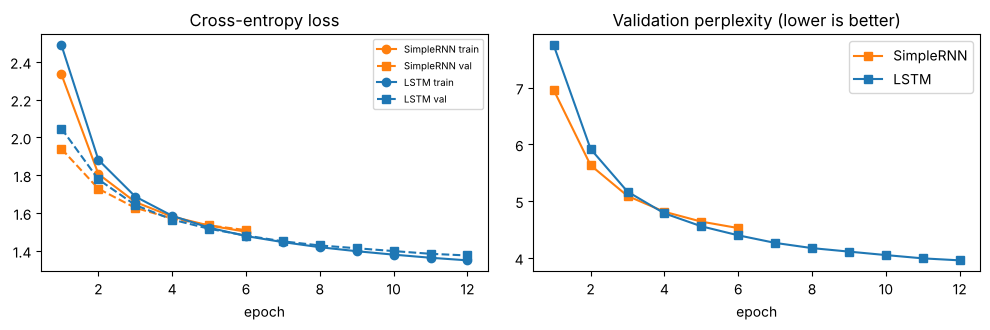

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, c in (("SimpleRNN", "tab:orange"), ("LSTM", "tab:blue")):
    e = range(1, len(hist[k]["loss"]) + 1)
    ax[0].plot(e, hist[k]["loss"], "o-", c=c, label=k + " train"); ax[0].plot(e, hist[k]["val_loss"], "s--", c=c, label=k + " val")
    ax[1].plot(e, np.exp(hist[k]["val_loss"]), "s-", c=c, label=k)
ax[0].set(title="Cross-entropy loss", xlabel="epoch"); ax[0].legend(fontsize=7)
ax[1].set(title="Validation perplexity (lower is better)", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Generating text
Starting from a seed string, we repeatedly predict a distribution over the next character, divide the logits by a
**temperature** $T$ and sample. Low $T$ gives safe, repetitive text; high $T$ gives creative but error-prone text.

In [6]:
def generate(model, seed, n=400, temperature=1.0):
    ids = [c2i[c] for c in seed]
    out = list(seed)
    for _ in range(n):
        logits = model(np.array([ids[-SEQ:]]), training=False)[0, -1].numpy() / temperature
        p = np.exp(logits - logits.max()); p /= p.sum()
        nxt = np.random.choice(V, p=p)
        ids.append(nxt); out.append(i2c[nxt])
    return "".join(out)
np.random.seed(5)
print("generate() defined; sampling with temperature scaling")

generate() defined; sampling with temperature scaling


In [7]:
seed = "ROMEO:\n"
for T in (0.3, 0.7, 1.0):
    print(f"======== LSTM, temperature {T} ========")
    print(generate(models["LSTM"], seed, 350, T), "\n")

======== LSTM, temperature 0.3 ========


ROMEO:
I have seen the man that a word will not stocks thee
And the sun and the gods of his hearts
And take the season of this place of the hands
And think to the company to me to the people,
To see the sea than the fire of words.

CORIOLANUS:
Why, then I say the gates of my worship,
And seem the child of that made to the people,
Which the prince that hav 

======== LSTM, temperature 0.7 ========


ROMEO:
I have sent the man hath thousand to know.

Lord Rastio:
Be, give me here to hear me, and make you are ready
Than the countress of me a soul too thee,
Which some which command as he hath made the sun
Which hanged him or to the shapes, let thee and
But or one than the chopper of a father's by
As I will tell in repersed, that it is
report of good liv 

======== LSTM, temperature 1.0 ========


ROMEO:
I am wailt a God, make my blood upon this boot,
I knew it in pird,
Dakes him now we once, 'tis dreame?
To my viewan, lamentation.

LUCIO:
Why, what I now, pass! he is. What seem'd sheph
some father, say to our lurder of in all,
And in the morns to make thee changing.

CAPULET:
A meaning to live to the Edward,
Lived man we shall pitius dead of porit 



In [8]:
np.random.seed(5)
for k in ("SimpleRNN", "LSTM"):
    print(f"======== {k} ========")
    print(generate(models[k], "First Citizen:\n", 300, 0.7), "\n")

======== SimpleRNN ========


First Citizen:
His like a slave,
The head woo my braves to Fither made you prove me the grace! who didst them much you, sir; but thou sings and the galling the worshy mele mean'd with thy heart!

DUKE VINCENTIO:
He had for the mind, that they arance to-morrow he heart, when they be putsenger'd the counten are desi 

======== LSTM ========


First Citizen:
You may canst the company; and therefore stay your father,
Or slain hath strew your prince to supper them
Hath determined with him: boy know I have gates,
And laid the countress of me a soul!
What entreat a strange?

SICINIUS:
We have send me seendly.

PARIS:
Poor God, then thou wert passay heart
As 



model       temp  words found in training vocabulary
SimpleRNN    0.3   99.3%
SimpleRNN    0.7   88.5%
SimpleRNN    1.0   76.1%
SimpleRNN    1.3   61.3%
LSTM         0.3   97.7%
LSTM         0.7   95.0%
LSTM         1.0   77.8%
LSTM         1.3   69.5%


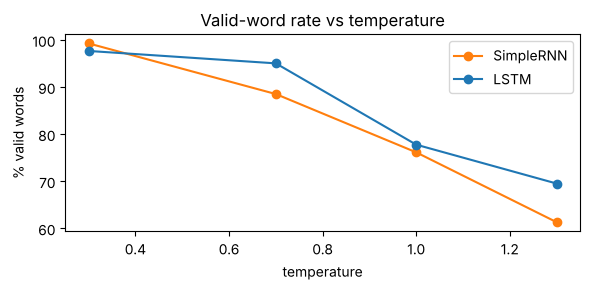

In [9]:
vocab_words = set(text.lower().replace("\n", " ").split())
def real_word_rate(s):
    w = [x.strip(".,;:!?'\"") for x in s.lower().replace("\n", " ").split()]
    w = [x for x in w if x]
    return sum(x in vocab_words for x in w) / max(1, len(w))
rows = []
np.random.seed(1)
for k in ("SimpleRNN", "LSTM"):
    for T in (0.3, 0.7, 1.0, 1.3):
        s = generate(models[k], "ROMEO:\n", 600, T)
        rows.append((k, T, real_word_rate(s)))
print(f"{'model':10s} {'temp':>5s}  words found in training vocabulary")
for k, T, r in rows: print(f"{k:10s} {T:5.1f}  {100 * r:5.1f}%")
fig, ax = plt.subplots(figsize=(6, 3))
for k, c in (("SimpleRNN", "tab:orange"), ("LSTM", "tab:blue")):
    ax.plot([r[1] for r in rows if r[0] == k], [100 * r[2] for r in rows if r[0] == k], "o-", c=c, label=k)
ax.set(xlabel="temperature", ylabel="% valid words", title="Valid-word rate vs temperature"); ax.legend()
plt.tight_layout(); plt.show()